# Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
# from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer

# Loading Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arunasivapragasam/donors-choose")

print("Path to dataset files:", path)

100%|██████████| 40.7M/40.7M [00:00<00:00, 129MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/arunasivapragasam/donors-choose/versions/3


In [ ]:
import os

print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "Preprocessed_DonorsChoose_dataset.csv"))


['Preprocessed_DonorsChoose_dataset.csv']


# 1. Data Exploration and Preparation

In [ ]:
df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [ ]:
df.tail()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,1,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,1,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,1,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,1,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0
109247,p191189,ms,va,grades_6_8,appliedlearning_math_science,college_careerprep_mathematics,0,1,109.90,5,classroom tech develop 21st century leaders,last time used math probably within last hour ...,students_need_opportunities_work_technology_or...,1


In [ ]:
# Shape of the data
df.shape

(109248, 14)

In [ ]:
# Column names
df.columns.tolist()

['id',
 'teacher_prefix',
 'school_state',
 'project_grade_category',
 'project_subject_categories',
 'project_subject_subcategories',
 'teacher_number_of_previously_posted_projects',
 'project_is_approved',
 'price',
 'quantity',
 'cleaned_titles',
 'cleaned_essays',
 'cleaned_summary',
 'isdigit_summary']

In [ ]:
# Summary
df.describe()

,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,isdigit_summary
count,109248.000000,109248.000000,109248.000000,109248.000000,109248.000000
mean,11.153165,0.848583,298.119343,16.965610,0.144222
std,27.777154,0.358456,367.498030,26.182942,0.351317
min,0.000000,0.000000,0.660000,1.000000,0.000000
25%,0.000000,1.000000,104.310000,4.000000,0.000000
50%,2.000000,1.000000,206.220000,9.000000,0.000000
75%,9.000000,1.000000,379.000000,21.000000,0.000000
max,451.000000,1.000000,9999.000000,930.000000,1.000000


In [ ]:
# Data types
df.dtypes

,0
id,object
teacher_prefix,object
school_state,object
project_grade_category,object
project_subject_categories,object
project_subject_subcategories,object
teacher_number_of_previously_posted_projects,int64
project_is_approved,int64
price,float64
quantity,int64


In [ ]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109248 entries, 0 to 109247
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   id                                            109248 non-null  object 
 1   teacher_prefix                                109248 non-null  object 
 2   school_state                                  109248 non-null  object 
 3   project_grade_category                        109248 non-null  object 
 4   project_subject_categories                    109248 non-null  object 
 5   project_subject_subcategories                 109248 non-null  object 
 6   teacher_number_of_previously_posted_projects  109248 non-null  int64  
 7   project_is_approved                           109248 non-null  int64  
 8   price                                         109248 non-null  float64
 9   quantity                                      10

In [ ]:
# Checking Duplicate values
df.duplicated().sum()

np.int64(0)

In [ ]:
# Checking Missing Values
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


In [ ]:
# Percentage of Missing Values
(df.isna().sum()/len(df)*100)

,0
id,0.00000
teacher_prefix,0.00000
school_state,0.00000
project_grade_category,0.00000
project_subject_categories,0.00000
project_subject_subcategories,0.00000
teacher_number_of_previously_posted_projects,0.00000
project_is_approved,0.00000
price,0.00000
quantity,0.00000


In [ ]:
# Dropping missing values
df = df.dropna(subset=['cleaned_titles'])

In [ ]:
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


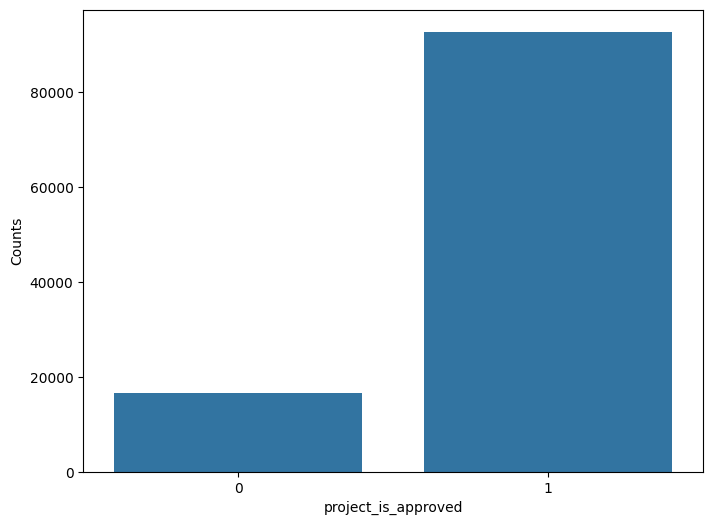

In [ ]:
# Checking the class imbalance
values_grade = df['project_is_approved'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("project_is_approved")
plt.ylabel("Counts")
plt.show()

## Data Splitting

In [ ]:
X = df.drop(columns='project_is_approved')
y = df['project_is_approved']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.4,stratify=y)

# 2. NLP Preprocessing Pipeline

In [ ]:
X

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0


In [ ]:
# Display all column names
print(X.columns.tolist())

['id', 'teacher_prefix', 'school_state', 'project_grade_category', 'project_subject_categories', 'project_subject_subcategories', 'teacher_number_of_previously_posted_projects', 'price', 'quantity', 'cleaned_titles', 'cleaned_essays', 'cleaned_summary', 'isdigit_summary']


In [ ]:
# Find columns related to text
text_columns = [
    col for col in X.columns
    if any(word in col.lower()
           for word in ['title', 'essay', 'summary', 'description', 'text'])
]

print("Text columns:", text_columns)